# Detección de errores de técnica en el remo con barra mediante Deep Learning

### Notebook 2 de 2. Variaciones y videos propios

Matías Martínez Moreno

12 de noviembre de 2026

---

Aquí no se entrena nada. Se usan los pesos, los umbrales y las predicciones del notebook 1.

| Parte | Qué responde |
|---|---|
| A. Variaciones | ¿Cómo cambia el desempeño con otra luz, nitidez o giro? |
| B. Videos propios | ¿Se mantienen el recall y la especificidad por repetición frente a la prueba? |

Aquí se prueba el modelo sin reentrenar con videos propios, comparando el recall y la especificidad por repetición con los de la prueba, y medir el efecto de cambios de luz, nitidez y giro.

## Ejecución

Se corre en Kaggle con 2 GPU T4 e Internet activo. Las entradas son la salida del notebook 1 y un dataset privado con los videos propios. La etiqueta sale del nombre del archivo (`bien`, `lumbar` o `torso`) y los jalones completos de cada video están en `REPETICIONES_ESPERADAS`.

In [1]:
# ============================================================
# Configuración de la corrida
# ============================================================
CORRER_VARIACIONES = True           # parte A: unos 10 a 20 min
CORRER_VIDEOS = True                # parte B: unos minutos por video
# Jalones COMPLETOS de cada video, comprobados sobre la curva de la muñeca de la corrida 1, sin mirar lo que marca el modelo: un jalón cortado al borde del video no cuenta.
# El autor había contado más porque incluyó los jalones cortados en el borde (bien_1 7, lumbar_1 7, torso_abajo_1 9); en torso_vertical_1 contó 9 y la curva muestra 8, sin un borde que lo explique.
# El conteo automático debe dar lo mismo, si no el video no se analiza.
REPETICIONES_ESPERADAS = {'remo_bien_1': 5, 'remo_lumbar_1': 6, 'remo_lumbar_2': 7, 'remo_torso_abajo_1': 8, 'remo_torso_abajo_2': 4, 'remo_torso_vertical_1': 8, 'remo_torso_gym_1': 9}
REPETICIONES_OTROS = 10             # para un video que no esté en la lista de arriba. None: no revisar su conteo
MINIMO_REPS = 4                     # un video con menos repeticiones que esto no entra en las métricas
ACEPTAR_CONTEO_DISTINTO = False     # True: calcula métricas aunque el conteo no dé (sigue valiendo el mínimo). se declara como limitación
PICOS = dict(distancia=12, prominencia_relativa=.25, minimo_px=5)      # cómo se separan los jalones. Se ajusta ANTES de ver resultados
TRAMOS = {}                         # opcional, en segundos: {'remo_torso_1.mov': [(0, 30), (36, 62)]}. Cada tramo se cuenta aparte y lo de afuera (una pausa) no cuenta. Se ajusta ANTES de ver resultados

In [2]:
%pip uninstall -y -q onnxruntime
%pip install -q --no-deps rtmlib==0.0.16
%pip install -q onnxruntime-gpu==1.23.2

In [3]:
# ============================================================
# Librerías, configuración y utilidades (el mismo código del notebook 1)
# ============================================================
import os, sys, json, time, math, shutil, zipfile, threading, warnings, html, uuid, platform, pickle
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F, timm
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from sklearn.metrics import average_precision_score, precision_recall_curve

warnings.filterwarnings('ignore'); cv2.setNumThreads(1)
T0 = time.time()
PRUEBA = os.environ.get('FAQA_PRUEBA') == '1'          # prueba local de la lógica: datos sintéticos, pose falsa y redes diminutas
if PRUEBA:
    torch.set_num_threads(2)
ENTRADA = Path(os.environ.get('FAQA_INPUT', '/kaggle/input'))
WORK = Path(os.environ.get('FAQA_WORK', '/tmp/remo')); OUT = Path(os.environ.get('FAQA_OUT', '/kaggle/working/outputs'))
for d in ['figuras', 'tablas']:
    (OUT / d).mkdir(parents=True, exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)
DEVS = [f'cuda:{i}' for i in range(torch.cuda.device_count())] or ['cpu']
ERR = ['lumbar', 'torso']; NOMBRE_ERR = {'lumbar': 'Lumbar', 'torso': 'Torso'}
NOTAS, TIEMPOS = [], {}
BOOT = 20 if PRUEBA else 1000                          # remuestreos del bootstrap por clip
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold'})
ESQUELETO = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (0, 5), (0, 6)]


def horas():
    return (time.time() - T0) / 3600


def recorrer(raiz):
    """Archivos bajo `raiz`, entrando en carpetas enlazadas (así monta Kaggle los inputs)."""
    for d, _, fs in os.walk(raiz, followlinks=True):
        for f in sorted(fs):
            yield Path(d) / f


class Seguro:
    """Si un análisis falla, se anota en NOTAS y la corrida sigue (en la prueba local sí se detiene)."""
    def __init__(self, n): self.n = n
    def __enter__(self): return self
    def __exit__(self, t, ex, tb):
        if ex is None or PRUEBA or not isinstance(ex, Exception):
            return False
        import traceback; traceback.print_exception(t, ex, tb)
        NOTAS.append(f'Falló «{self.n}»: {str(ex)[:120]}'); return True


class Etapa:
    def __init__(self, n): self.n = n
    def __enter__(self): self.t = time.time(); print(f'── {self.n} · {horas():.2f} h'); return self
    def __exit__(self, *a): TIEMPOS[self.n] = (time.time() - self.t) / 60; print(f'── {self.n}: {TIEMPOS[self.n]:.1f} min')


def guardar_fig(fig, nombre):
    if not PRUEBA:             # en la prueba local no se dibujan los archivos: así tarda segundos
        fig.savefig(OUT / 'figuras' / f'{nombre}.png', dpi=130, bbox_inches='tight')
    plt.show(); plt.close(fig)


def guardar_tabla(df, nombre):
    df.to_csv(OUT / 'tablas' / f'{nombre}.csv', index=False); display(df)


def limpio(o):
    """Convierte resultados a algo que JSON pueda guardar."""
    if isinstance(o, dict): return {str(k): limpio(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpio(v) for v in o]
    if isinstance(o, np.ndarray): return None
    if isinstance(o, (np.floating, float)): return float(o) if np.isfinite(o) else None
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o if isinstance(o, (str, int, bool, type(None))) else str(o)


if not PRUEBA:
    assert torch.cuda.is_available(), 'No hay GPU: Settings → Accelerator → GPU T4 x2'
print(f'PyTorch {torch.__version__} · GPU: {[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]} · prueba local: {PRUEBA}')

from scipy.signal import find_peaks
from scipy.stats import beta
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

LADO_MAX, RES_GUARDA, UMB_KP = 640, (96 if PRUEBA else 384), 0.3
RECORTES = ['completa', 'persona', 'tronco']
ZPTS = {'persona': list(range(17)), 'tronco': [5, 6, 11, 12, 13, 14]}
MARG = {'persona': 1.15, 'tronco': 1.25}


class Pose:
    """RTMPose (rtmlib + onnxruntime). No hay plan B: si no carga, el notebook se detiene y nunca se mezclan dos estimadores."""
    def __init__(self, dev):
        self.tipo, self.proveedor, self.n = ('falsa', 'ninguno', 0) if PRUEBA else (None, None, 0)
        if PRUEBA:
            return
        import onnxruntime as ort
        if hasattr(ort, 'preload_dlls'):
            try: ort.preload_dlls()
            except Exception: pass
        from rtmlib import Body
        self.m = Body(mode='balanced', backend='onnxruntime', device=dev)          # «cuda:1» usa la segunda GPU (rtmlib 0.0.16)
        self.m(np.zeros((256, 256, 3), np.uint8)); self.tipo = 'rtmpose'
        self.proveedor = self.m.pose_model.session.get_providers()[0]

    def __call__(self, im):
        H, W = im.shape[:2]
        if self.tipo == 'falsa':
            self.n += 1; r = np.random.default_rng(self.n)
            base = np.array([[.5, .15]] * 5 + [[.42, .3], [.58, .3], [.4, .45], [.6, .45], [.4, .55], [.6, .55],
                             [.45, .55], [.55, .55], [.45, .72], [.55, .72], [.45, .9], [.55, .9]], np.float32)
            k = (base + r.normal(0, .005, base.shape)) * [W, H]
            k[[9, 10], 1] = H * (.6 + .15 * math.cos(2 * math.pi * self.n / 15))     # las muñecas suben y bajan: un jalón cada 15 fotogramas
            return [np.concatenate([k, np.full((17, 1), .9)], 1).astype(np.float32)]
        k, s = self.m(im)
        k = np.asarray(k, np.float32).reshape(-1, 17, 2); s = np.asarray(s, np.float32).reshape(-1, 17)
        return list(np.concatenate([k, np.clip(s, 0, 1)[..., None]], -1))


def principal(dets, H, W):
    """La persona más grande, centrada y nítida."""
    mejor, kp = -1, np.zeros((17, 3), np.float32)
    for k in dets:
        v = k[:, 2] > UMB_KP
        if v.sum() < 3:
            continue
        p = k[v, :2]; x0, y0 = p.min(0); x1, y1 = p.max(0)
        c = 1 - min(1, 1.5 * math.hypot((x0 + x1) / 2 / W - .5, (y0 + y1) / 2 / H - .5))
        sc = (x1 - x0) * (y1 - y0) / (H * W) * (.5 + .5 * c) * float(k[:, 2].mean())
        if sc > mejor:
            mejor, kp = sc, k
    return kp


def caja(kp, rec, H, W):
    if rec != 'completa':
        p = kp[ZPTS[rec]]; p = p[p[:, 2] > UMB_KP]
        if len(p) >= 2:
            x0, y0 = p[:, :2].min(0); x1, y1 = p[:, :2].max(0)
            return np.array([(x0 + x1) / 2, (y0 + y1) / 2, max(x1 - x0, y1 - y0, .12 * max(H, W)) * MARG[rec]], np.float32)
    return np.array([W / 2, H / 2, max(H, W)], np.float32)


def recortar(img, c, out):
    s = out / max(float(c[2]), 1.0)
    M = np.float32([[s, 0, out / 2 - s * c[0]], [0, s, out / 2 - s * c[1]]])
    return cv2.warpAffine(img, M, (out, out), flags=cv2.INTER_LINEAR, borderValue=(114, 114, 114))      # warpAffine no admite INTER_AREA


def reducir(im):
    """Lado mayor a 640 px (transformación geométrica). Igual para fotos del dataset y fotogramas de video."""
    s = LADO_MAX / max(im.shape[:2])
    return cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else im


def leer_img(ruta):
    return reducir(cv2.imread(str(ruta), cv2.IMREAD_COLOR))


def recorte_jpg(im, c):
    """Recorte cuadrado a 384 px guardado en JPEG 92. Igual para fotos del dataset y fotogramas de video."""
    return cv2.imencode('.jpg', recortar(im, c, RES_GUARDA), [cv2.IMWRITE_JPEG_QUALITY, 92])[1].tobytes()

MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); DESV = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def decodificar(b, res):
    """JPEG del recorte → RGB a la resolución de la red (reescalado: transformación geométrica)."""
    im = cv2.imdecode(np.frombuffer(b, np.uint8), cv2.IMREAD_COLOR)[:, :, ::-1]
    return cv2.resize(im, (res, res), interpolation=cv2.INTER_AREA) if im.shape[0] != res else np.ascontiguousarray(im)


class Modelo(nn.Module):
    """CNN de timm sin su clasificador (entrega un vector por imagen) + cabeza densa de 2 logits, uno por error.
    La normalización con la media y la desviación de ImageNet (transformación fotométrica) va dentro del modelo."""
    def __init__(self, nombre_timm, preentrenada=True, drop_path=0.0):
        super().__init__()
        kw = dict(pretrained=preentrenada and not PRUEBA, num_classes=0)
        if drop_path:
            kw['drop_path_rate'] = drop_path
        self.red = timm.create_model(nombre_timm, **kw)
        self.cab = nn.Sequential(nn.Linear(self.red.num_features, 256), nn.GELU(), nn.Dropout(.2), nn.Linear(256, 2))
        self.register_buffer('media', MEDIA.clone()); self.register_buffer('desv', DESV.clone())
    def prep(self, x): return (x.float() / 255 - self.media) / self.desv
    def forward(self, x): return self.cab(self.red(self.prep(x)))


def cargar(ruta, nombre_timm, drop_path, dev):
    """Modelo con sus pesos guardados, listo para predecir."""
    m = Modelo(nombre_timm, preentrenada=False, drop_path=drop_path)
    m.load_state_dict(torch.load(ruta, map_location='cpu'))
    return m.to(dev).eval()

def umbral_f1(y, p):
    """Corte con el mayor F1. Solo se llama con datos de validación."""
    o = np.argsort(-p); ys = y[o]; tp = np.cumsum(ys); fp = np.cumsum(1 - ys)
    k = int(np.argmax(2 * tp / np.maximum(tp + fp + ys.sum(), 1))); return float(p[o][k])


def met(y, p, t):
    pr = p >= t; tp = int((pr & (y == 1)).sum()); fp = int((pr & (y == 0)).sum()); fn = int((~pr & (y == 1)).sum()); tn = len(y) - tp - fp - fn
    return dict(F1=2 * tp / max(2 * tp + fp + fn, 1), Precision=tp / max(tp + fp, 1), Recall=tp / max(tp + fn, 1), Especificidad=tn / max(tn + fp, 1),
                AP=average_precision_score(y, p) if 0 < y.sum() < len(y) else np.nan, tp=tp, fp=fp, fn=fn, tn=tn)


def remuestras_clip(cl, B, semilla=0):
    """Bootstrap por clip: se sortean clips completos, porque las fotos de un mismo clip se parecen entre sí."""
    ug, inv = np.unique(cl, return_inverse=True); por = [np.where(inv == g)[0] for g in range(len(ug))]
    rng = np.random.default_rng(semilla)
    return [np.concatenate([por[g] for g in rng.integers(0, len(ug), len(ug))]) for _ in range(B)]


def ic(y, p, t, cl, B=None):
    """Intervalo del 95 % (percentiles 2,5 y 97,5) de cada métrica."""
    acum = defaultdict(list)
    for idx in remuestras_clip(cl, B or BOOT):
        r = met(y[idx], p[idx], t)
        for k in ('F1', 'Precision', 'Recall', 'Especificidad', 'AP'):
            if np.isfinite(r[k]):
                acum[k].append(r[k])
    return {k: (np.percentile(acum[k], [2.5, 97.5]) if acum[k] else np.array([np.nan, np.nan])) for k in ('F1', 'Precision', 'Recall', 'Especificidad', 'AP')}


def txt_ic(v):
    return f'{v[0]:.2f}–{v[1]:.2f}'


def ap_err(idx, P, split):
    """AP de cada error en las fotos `idx` que pertenecen a `split`."""
    r = {}
    for j, e in enumerate(ERR):
        m = S[idx, j] == split
        r[e] = average_precision_score(Y[idx][m, j], P[m, j]) if m.any() and 0 < Y[idx][m, j].sum() < m.sum() else np.nan
    return r


def por_clip(idx, P, j, split):
    """De foto a repetición: el clip tiene el error si alguna foto lo tiene, y su puntaje es la foto más probable."""
    m = S[idx, j] == split; c = CLIP[idx][m]; y = Y[idx][m, j]; p = P[m, j]
    u = np.unique(c); return np.array([y[c == k].max() for k in u]), np.array([p[c == k].max() for k in u])


def tabla_por_repeticion(umb):
    """Métricas por repetición en la prueba, con la regla y los umbrales congelados."""
    filas = []
    for j, e in enumerate(ERR):
        yt, pt = por_clip(ITE, P_TEST, j, 'test'); r = met(yt, pt, umb[e]); c_ = ic(yt, pt, umb[e], np.arange(len(yt)))
        filas.append(dict(Error=NOMBRE_ERR[e], Clips=len(yt), Con_error=int(yt.sum()), Recall=r['Recall'], Recall_IC=txt_ic(c_['Recall']),
                          Especificidad=r['Especificidad'], Especificidad_IC=txt_ic(c_['Especificidad']), F1=r['F1'], F1_IC=txt_ic(c_['F1']),
                          Precision=r['Precision'], Precision_IC=txt_ic(c_['Precision']), AP=r['AP'], AP_IC=txt_ic(c_['AP']), tp=r['tp'], fp=r['fp'], fn=r['fn'], tn=r['tn'], Umbral=umb[e]))
    return pd.DataFrame(filas)

if PRUEBA:
    REPETICIONES_ESPERADAS = {}; REPETICIONES_OTROS = 4; MINIMO_REPS = 1
    PICOS = dict(distancia=5, prominencia_relativa=.25, minimo_px=2)

PyTorch 2.11.0+cu130 · GPU: ['Tesla T4', 'Tesla T4'] · prueba local: False


## Cargar lo que dejó el notebook 1

In [4]:
with Etapa('cargar resultados del notebook 1'):
    candidatos = [p for p in recorrer(ENTRADA) if p.name == 'config.json' and p.parent.name == 'para_validaciones']
    assert candidatos, 'No encontré para_validaciones/config.json: Add Input → Notebooks → remo_entrenamiento'
    if len(candidatos) > 1:
        print('⚠ Hay varias salidas del notebook 1; uso la primera:', candidatos[0])
    PV = candidatos[0].parent; RAIZ_NB1 = PV.parent
    CFG = json.load(open(PV / 'config.json', encoding='utf-8'))
    assert (CFG['res_guarda'], CFG['lado_max'], CFG['umb_kp']) == (RES_GUARDA, LADO_MAX, UMB_KP), 'El preprocesamiento no coincide con el del notebook 1'
    ind = pd.read_csv(PV / 'indice.csv', dtype=str, keep_default_na=False)
    IDS = ind['id'].tolist(); CLIP = ind['clip'].values.astype(str); SPLIT = ind['split'].values.astype('<U5')
    S = np.stack([ind['s_lumbar'].values, ind['s_torso'].values], 1).astype('<U5')
    Y = np.stack([ind['y_lumbar'].astype(float).values, ind['y_torso'].astype(float).values], 1).astype(np.float32)
    RAZON = pd.to_numeric(ind['razon'], errors='coerce').values; VISTA = ind['vista'].values.astype(str)
    IVA, ITE = np.where(SPLIT == 'val')[0], np.where(SPLIT == 'test')[0]
    Z = np.load(PV / 'predicciones_final.npz')
    P_VAL, P_TEST = Z['P_val'], Z['P_test']
    RC = pickle.load(open(PV / 'recortes_val_test.pkl', 'rb')); CROPS_VAL, CROPS_TE = RC['val'], RC['test']; del RC
    T_FINAL = pd.read_csv(PV / 'test_final_exacto.csv')
    REC, RES_F = CFG['recorte'], CFG['res']
    UMB_FOTO, UMB_REP = CFG['umbrales_por_foto'], CFG['umbrales_por_repeticion']
    if (PV / 'test_por_repeticion_exacto.csv').exists():
        T_REP = pd.read_csv(PV / 'test_por_repeticion_exacto.csv')
    else:          # el notebook 1 no la pudo calcular: se saca de sus predicciones, con los mismos umbrales
        T_REP = tabla_por_repeticion(UMB_REP); NOTAS.append('La tabla por repetición se recalculó aquí: el notebook 1 no la dejó.')
    # Cada GPU carga parte de las semillas; así predicen a la vez.
    MODS = {d: [] for d in DEVS}
    for k, c in enumerate(CFG['modelos_final']):
        d_ = DEVS[k % len(DEVS)]
        MODS[d_].append(cargar(RAIZ_NB1 / 'modelos' / f"{c['nombre']}.pt", c['timm'], c.get('drop_path', 0), d_))
print(f"Modelo final: {CFG['nombre_final']} · recorte «{REC}» · {len(CFG['modelos_final'])} semillas · {len(IDS)} fotos en el índice · pose {CFG['metodo_pose']}")
display(pd.DataFrame([dict(Error=NOMBRE_ERR[e], Umbral_por_foto=UMB_FOTO[e], Umbral_por_repeticion=UMB_REP[e]) for e in ERR]).round(3))


def fotos_de(crops, transformar=None):
    """Recortes guardados → lote de fotos: reescalado (geométrica) y, si se pide, una variación. La normalización va dentro del modelo."""
    def una(par):
        i, b = par
        x = decodificar(b, RES_F)
        if transformar is not None:
            x = transformar(x, i)
        return np.ascontiguousarray(x)
    with ThreadPoolExecutor(4) as pool:
        return torch.from_numpy(np.stack(list(pool.map(una, enumerate(crops))))).permute(0, 3, 1, 2)


@torch.no_grad()
def prob_modelo(m, X, dev, lote=64):
    """Probabilidad de una semilla: promedio de la foto y su espejo, igual que en el notebook 1."""
    m.eval(); salida = []
    for vol in (False, True):
        P = []
        for a in range(0, len(X), lote):
            x = X[a:a + lote].to(dev)
            if vol:
                x = x.flip(3)
            with torch.autocast('cuda', torch.float16, enabled=dev != 'cpu'):
                P.append(torch.sigmoid(m(x.contiguous(memory_format=torch.channels_last)).float()).cpu().numpy())
        salida.append(np.concatenate(P))
    return np.mean(salida, 0)


def ensamble(X):
    """Probabilidad del modelo final: promedio de las semillas."""
    partes = {}

    def trabajar(d):
        partes[d] = [prob_modelo(m, X, d) for m in MODS[d]]

    hs = [threading.Thread(target=trabajar, args=(d,)) for d in DEVS]
    [h.start() for h in hs]; [h.join() for h in hs]
    assert len(partes) == len(DEVS), 'Falló la predicción en alguna GPU'
    return np.mean([p for v in partes.values() for p in v], 0)

── cargar resultados del notebook 1 · 0.00 h
── cargar resultados del notebook 1: 0.2 min
Modelo final: FINAL (ConvNeXt-S · completa · ensamble de 5) · recorte «tronco» · 5 semillas · 18201 fotos en el índice · pose rtmpose


,Error,Umbral_por_foto,Umbral_por_repeticion
0,Lumbar,0.332,0.648
1,Torso,0.625,0.400


# A. ¿Cómo cambia el desempeño si cambia la imagen?

Se cambia una sola cosa a la vez en las fotos de prueba y se predice con el modelo final, sin entrenar con ellas ni decidir nada. La variación se aplica después del recorte y el reescalado, y antes de la normalización.

| Cambio | Categoría | Tipo de transformación | Qué simula |
|---|---|---|---|
| Más oscura (×0,5) | iluminación | fotométrica | poca luz |
| Más clara (×1,6) | iluminación | fotométrica | luz fuerte, zonas quemadas |
| Bajo contraste | iluminación | fotométrica | luz plana o lente sucio |
| Desenfoque leve y fuerte | nitidez | fotométrica | foto movida o sin enfoque |
| Giro de ±5°, ±10° y ±20° | giro | geométrica | celular torcido |

Se mide cuánto cae la AP frente a la prueba original, con un IC 95 % pareado por clip. Si el intervalo no cruza el cero, la caída es consistente. También se miden el recall y la especificidad por repetición con el umbral ya fijado. El giro cambia el ángulo real del torso sin cambiar la etiqueta, así que parte de la caída en torso puede ser lógica.

── A · variaciones · 0.01 h


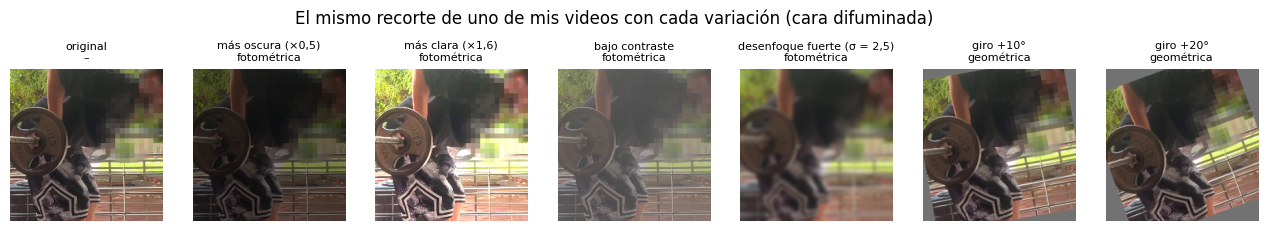

[0.02 h] original listo
[0.04 h] más oscura (×0,5) listo
[0.05 h] más clara (×1,6) listo
[0.07 h] bajo contraste listo
[0.08 h] desenfoque leve (σ = 1) listo
[0.10 h] desenfoque fuerte (σ = 2,5) listo
[0.11 h] giro +5° listo
[0.12 h] giro −5° listo
[0.14 h] giro +10° listo
[0.15 h] giro −10° listo
[0.17 h] giro +20° listo
[0.18 h] giro −20° listo


,Cambio,Categoria,Tipo,Error,AP,Caida_AP,IC_bajo,IC_alto,Conclusion,AP_relativa,Recall_por_repeticion,Especificidad_por_repeticion
0,original,sin cambio,–,Lumbar,0.931,0.000,0.000,0.000,sin cambio,1.000,0.845,0.943
1,original,sin cambio,–,Torso,0.817,0.000,0.000,0.000,sin cambio,1.000,0.814,0.869
2,"más oscura (×0,5)",iluminación,fotométrica,Lumbar,0.932,-0.001,-0.005,0.004,sin diferencia consistente,1.001,0.845,0.943
3,"más oscura (×0,5)",iluminación,fotométrica,Torso,0.820,-0.003,-0.022,0.012,sin diferencia consistente,1.003,0.829,0.864
4,"más clara (×1,6)",iluminación,fotométrica,Lumbar,0.909,0.022,0.008,0.041,baja,0.976,0.869,0.911
5,"más clara (×1,6)",iluminación,fotométrica,Torso,0.812,0.005,-0.013,0.026,sin diferencia consistente,0.994,0.843,0.864
6,bajo contraste,iluminación,fotométrica,Lumbar,0.930,0.001,-0.003,0.004,sin diferencia consistente,0.999,0.857,0.943
7,bajo contraste,iluminación,fotométrica,Torso,0.822,-0.005,-0.014,0.004,sin diferencia consistente,1.006,0.814,0.864
8,desenfoque leve (σ = 1),nitidez,fotométrica,Lumbar,0.926,0.005,-0.003,0.016,sin diferencia consistente,0.995,0.869,0.932
9,desenfoque leve (σ = 1),nitidez,fotométrica,Torso,0.816,0.001,-0.014,0.015,sin diferencia consistente,0.999,0.814,0.854


Sin variación, las predicciones coinciden con las del notebook 1: diferencia máxima 4.9e-04


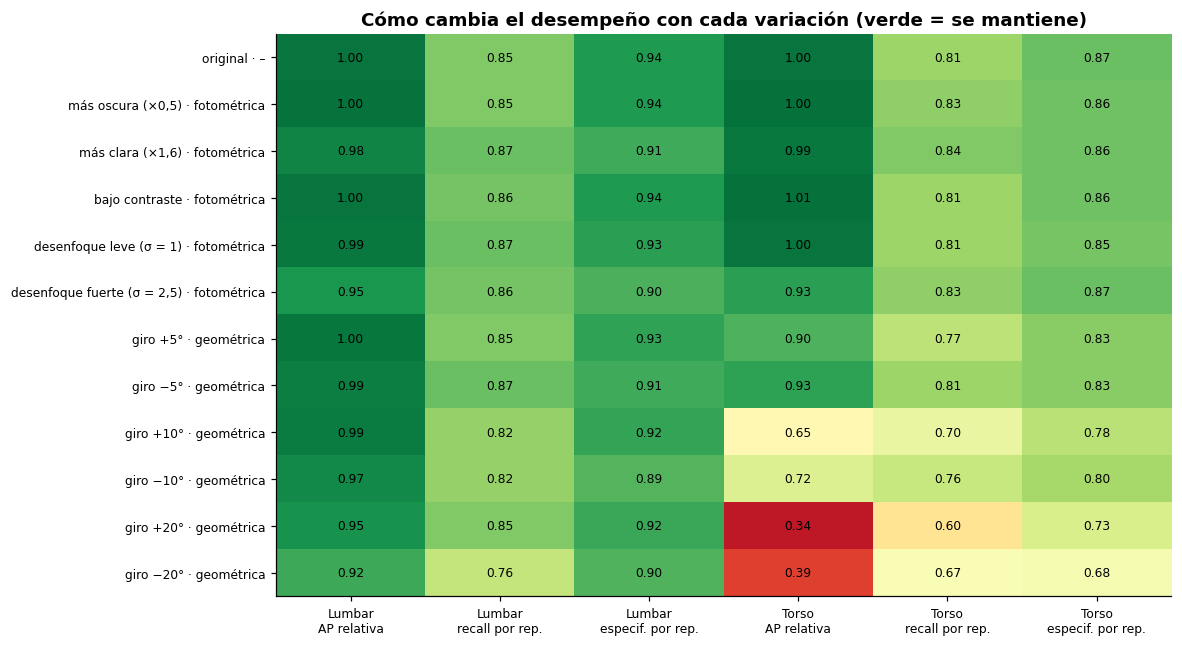

── A · variaciones: 10.4 min


In [8]:
def _rot(x, a):
    L = x.shape[0]; return cv2.warpAffine(x, cv2.getRotationMatrix2D((L / 2, L / 2), a, 1), (L, L), borderValue=(114, 114, 114))


CAMBIOS = [('original', 'sin cambio', '–', None),
           ('más oscura (×0,5)', 'iluminación', 'fotométrica', lambda x, i: (x * .5).astype(np.uint8)),
           ('más clara (×1,6)', 'iluminación', 'fotométrica', lambda x, i: np.clip(x * 1.6, 0, 255).astype(np.uint8)),
           ('bajo contraste', 'iluminación', 'fotométrica', lambda x, i: (x * .5 + 64).astype(np.uint8)),
           ('desenfoque leve (σ = 1)', 'nitidez', 'fotométrica', lambda x, i: cv2.GaussianBlur(x, (0, 0), 1)),
           ('desenfoque fuerte (σ = 2,5)', 'nitidez', 'fotométrica', lambda x, i: cv2.GaussianBlur(x, (0, 0), 2.5))]
for g_ in (5, 10, 20):
    CAMBIOS += [(f'giro +{g_}°', 'giro', 'geométrica', lambda x, i, a=g_: _rot(x, a)), (f'giro −{g_}°', 'giro', 'geométrica', lambda x, i, a=g_: _rot(x, -a))]


def dif_ap(Pa, Pb, j):
    """Diferencia de AP (A − B) en las mismas fotos, con intervalo del 95 % por clip."""
    m = S[ITE, j] == 'test'; y, a, b, cl = Y[ITE][m, j], Pa[m, j], Pb[m, j], CLIP[ITE][m]
    d = [average_precision_score(y[i], a[i]) - average_precision_score(y[i], b[i]) for i in remuestras_clip(cl, BOOT, 1) if 0 < y[i].sum() < len(i)]
    return (np.percentile(d, [2.5, 97.5]) if d else np.array([np.nan, np.nan]))


T_VAR = pd.DataFrame()
if CORRER_VARIACIONES:
    with Etapa('A · variaciones'), Seguro('Variaciones'):
        with Seguro('Figura de ejemplo'):
            sel_ = [c for c in CAMBIOS if c[0] in ('original', 'más oscura (×0,5)', 'más clara (×1,6)', 'bajo contraste', 'desenfoque fuerte (σ = 2,5)', 'giro +10°', 'giro +20°')]
            k0 = int(np.where(Y[ITE, 0] == 1)[0][0]) if (Y[ITE, 0] == 1).any() else 0
            fig, ax = plt.subplots(1, len(sel_), figsize=(2.3 * len(sel_), 2.8))
            for a_, (n_, cat_, tip_, tf) in zip(ax, sel_):
                x_ = decodificar(CROPS_TE[k0], RES_F); x_ = tf(x_, 0) if tf else x_
                a_.imshow(x_); a_.axis('off'); a_.set_title(f'{n_}\n{tip_}', fontsize=8)
            fig.suptitle('La misma foto de prueba con cada variación'); guardar_fig(fig, 'fig_variaciones_ejemplo')
        filas, P_ORIG = [], None
        for n_, cat_, tip_, tf in CAMBIOS:
            P_ = ensamble(fotos_de(CROPS_TE, tf))
            P_ORIG = P_ if P_ORIG is None else P_ORIG
            a_ = ap_err(ITE, P_, 'test')
            for j, e in enumerate(ERR):
                yr, pr2 = por_clip(ITE, P_, j, 'test'); r_ = met(yr, pr2, UMB_REP[e])
                ci_ = dif_ap(P_ORIG, P_, j) if tf is not None else np.array([0., 0.])
                caida = ap_err(ITE, P_ORIG, 'test')[e] - a_[e]
                filas.append(dict(Cambio=n_, Categoria=cat_, Tipo=tip_, Error=NOMBRE_ERR[e], AP=a_[e], Caida_AP=caida, IC_bajo=ci_[0], IC_alto=ci_[1],
                                  Conclusion='sin cambio' if tf is None else ('baja' if ci_[0] > 0 else ('sube' if ci_[1] < 0 else 'sin diferencia consistente')),
                                  AP_relativa=a_[e] / ap_err(ITE, P_ORIG, 'test')[e], Recall_por_repeticion=r_['Recall'], Especificidad_por_repeticion=r_['Especificidad']))
            print(f'[{horas():.2f} h] {n_} listo', flush=True)
        T_VAR = pd.DataFrame(filas); guardar_tabla(T_VAR.round(3), 'variaciones')
        d_ = float(np.abs(P_ORIG - P_TEST).max())
        print(f'Sin variación, las predicciones coinciden con las del notebook 1: diferencia máxima {d_:.1e}')
        if d_ >= .01:
            NOTAS.append(f'Las predicciones sin variación difieren de las del notebook 1 en {d_:.3f}: revisar.')
        nom_ = [c[0] for c in CAMBIOS]; cols_ = [('AP_relativa', 'AP relativa'), ('Recall_por_repeticion', 'recall por rep.'), ('Especificidad_por_repeticion', 'especif. por rep.')]
        M_v = np.array([[T_VAR[(T_VAR.Cambio == n_) & (T_VAR.Error == NOMBRE_ERR[e])][c_].iloc[0] for e in ERR for c_, _ in cols_] for n_ in nom_], dtype=float)
        fig, ax = plt.subplots(figsize=(10.5, .42 * len(nom_) + 1.6)); ax.imshow(M_v, cmap='RdYlGn', vmin=.3, vmax=1.02, aspect='auto')
        for a_ in range(M_v.shape[0]):
            for b_v in range(M_v.shape[1]):
                ax.text(b_v, a_, f'{M_v[a_, b_v]:.2f}', ha='center', va='center', fontsize=8)
        ax.set_yticks(range(len(nom_))); ax.set_yticklabels([f'{c[0]} · {c[2]}' for c in CAMBIOS], fontsize=8); ax.set_xticks(range(M_v.shape[1]))
        ax.set_xticklabels([f'{NOMBRE_ERR[e]}\n{t_}' for e in ERR for _, t_ in cols_], fontsize=8); ax.set_title('Cómo cambia el desempeño con cada variación (verde = se mantiene)')
        guardar_fig(fig, 'fig_variaciones')

### Ángulo de cámara en la prueba

Con la pose se estima si la foto es de perfil o más de frente (ancho de hombros dividido por largo del tronco) y se separan en tres grupos del mismo tamaño, más las fotos donde no se encontró pose. Las AP no se comparan directamente entre vistas porque la proporción de errores cambia en cada una, por eso se muestra también el azar. Lo que importa para los videos, que son de perfil, es cuántos errores hay en esa vista y cuántos se detectan. Es una medida aproximada en 2D y también varía con la postura.

In [9]:
T_VISTA = pd.DataFrame()
with Seguro('Ángulo de cámara'):
    filas = []
    for vv in ['de perfil', 'intermedia', 'más de frente', 'sin pose']:
        for j, e in enumerate(ERR):
            m = (VISTA[ITE] == vv) & (S[ITE, j] == 'test')
            if m.sum():
                y_ = Y[ITE][m, j]
                filas.append(dict(Vista=vv, Error=NOMBRE_ERR[e], Fotos=int(m.sum()), Con_error=int(y_.sum()), AP=average_precision_score(y_, P_TEST[m, j]) if 0 < y_.sum() < m.sum() else np.nan,
                                  AP_azar=float(y_.mean()), Recall=met(y_, P_TEST[m, j], UMB_FOTO[e])['Recall'], Especificidad=met(y_, P_TEST[m, j], UMB_FOTO[e])['Especificidad']))
    T_VISTA = pd.DataFrame(filas); guardar_tabla(T_VISTA.round(3), 'angulo_camara')

,Vista,Error,Fotos,Con_error,AP,AP_azar,Recall,Especificidad
0,de perfil,Lumbar,700,157,0.925,0.224,0.866,0.952
1,de perfil,Torso,864,37,0.733,0.043,0.514,0.992
2,intermedia,Lumbar,799,124,0.941,0.155,0.919,0.967
3,intermedia,Torso,916,62,0.848,0.068,0.855,0.978
4,más de frente,Lumbar,578,99,0.940,0.171,0.869,0.981
5,más de frente,Torso,683,120,0.889,0.176,0.858,0.959
6,sin pose,Lumbar,114,10,0.866,0.088,0.800,0.962
7,sin pose,Torso,122,16,0.256,0.131,0.250,0.962


# B. Videos propios

Los videos se grabaron con un iPhone 16 y se pasaron de `.mov` a `.mp4` H.264, porque el formato original no abría. A diferencia del dataset, que ya trae las fotos de cada repetición, a un video hay que hacerle tres pasos más. Se sacan 10 fotogramas por segundo, se separan los jalones con la altura de las muñecas y se toman 8 fotogramas por repetición. Desde ahí cada fotograma sigue el mismo camino que una foto del dataset (lado mayor a 640 px, RTMPose, recorte del tronco, 224 px, normalización y modelo final) con la misma regla y el mismo umbral. Ni el modelo ni los umbrales se ajustaron con los videos.

Hay cosas que no se pueden igualar. La etiqueta es el error hecho a propósito y no la de los autores, es una sola persona en dos lugares, hay más errores que en la prueba y los jalones se separan automáticamente. Por eso se usan recall y especificidad, que no cambian con la proporción de errores. Precisión, F1 y AP van solo como referencia.

## Paso 1. Contar las repeticiones antes de mirar el modelo

Primero se corre solo la pose. Un video entra a las métricas solo si el conteo coincide con sus jalones completos (`REPETICIONES_ESPERADAS`), que se fijaron sobre la curva de la muñeca sin mirar al modelo.

En la figura, a la izquierda hay un fotograma con la pose, que debe caer sobre la persona. A la derecha está la altura de las muñecas en el tiempo y cada línea gris es una repetición.

── B · pose y conteo · 0.18 h


load /root/.cache/rtmlib/hub/checkpoints/yolox_m_8xb8-300e_humanart-c2c7a14a.onnx with onnxruntime backend


load /root/.cache/rtmlib/hub/checkpoints/rtmpose-m_simcc-body7_pt-body7_420e-256x192-e48f03d0_20230504.onnx with onnxruntime backend
Pose con rtmpose · proveedor CUDAExecutionProvider


,Video,Etiqueta,Fotogramas,Segundos,Alto,Ancho,Pct_con_persona,Repeticiones,Esperadas,Se_analiza
0,remo_bien_1.mp4,bien,113,11.2,640,360,100.0,5,5,True
1,remo_lumbar_1.mp4,lumbar,149,14.8,640,360,100.0,6,6,True
2,remo_lumbar_2.mp4,lumbar,157,15.6,640,360,100.0,7,7,True
3,remo_torso_abajo_1.mp4,torso,170,16.9,640,360,100.0,8,8,True
4,remo_torso_abajo_2.mp4,torso,90,8.9,640,360,100.0,4,4,True
5,remo_torso_gym_1.mp4,torso,204,20.3,640,360,100.0,9,9,True
6,remo_torso_vertical_1.mp4,torso,160,15.9,640,360,100.0,8,8,True


── B · pose y conteo: 1.8 min


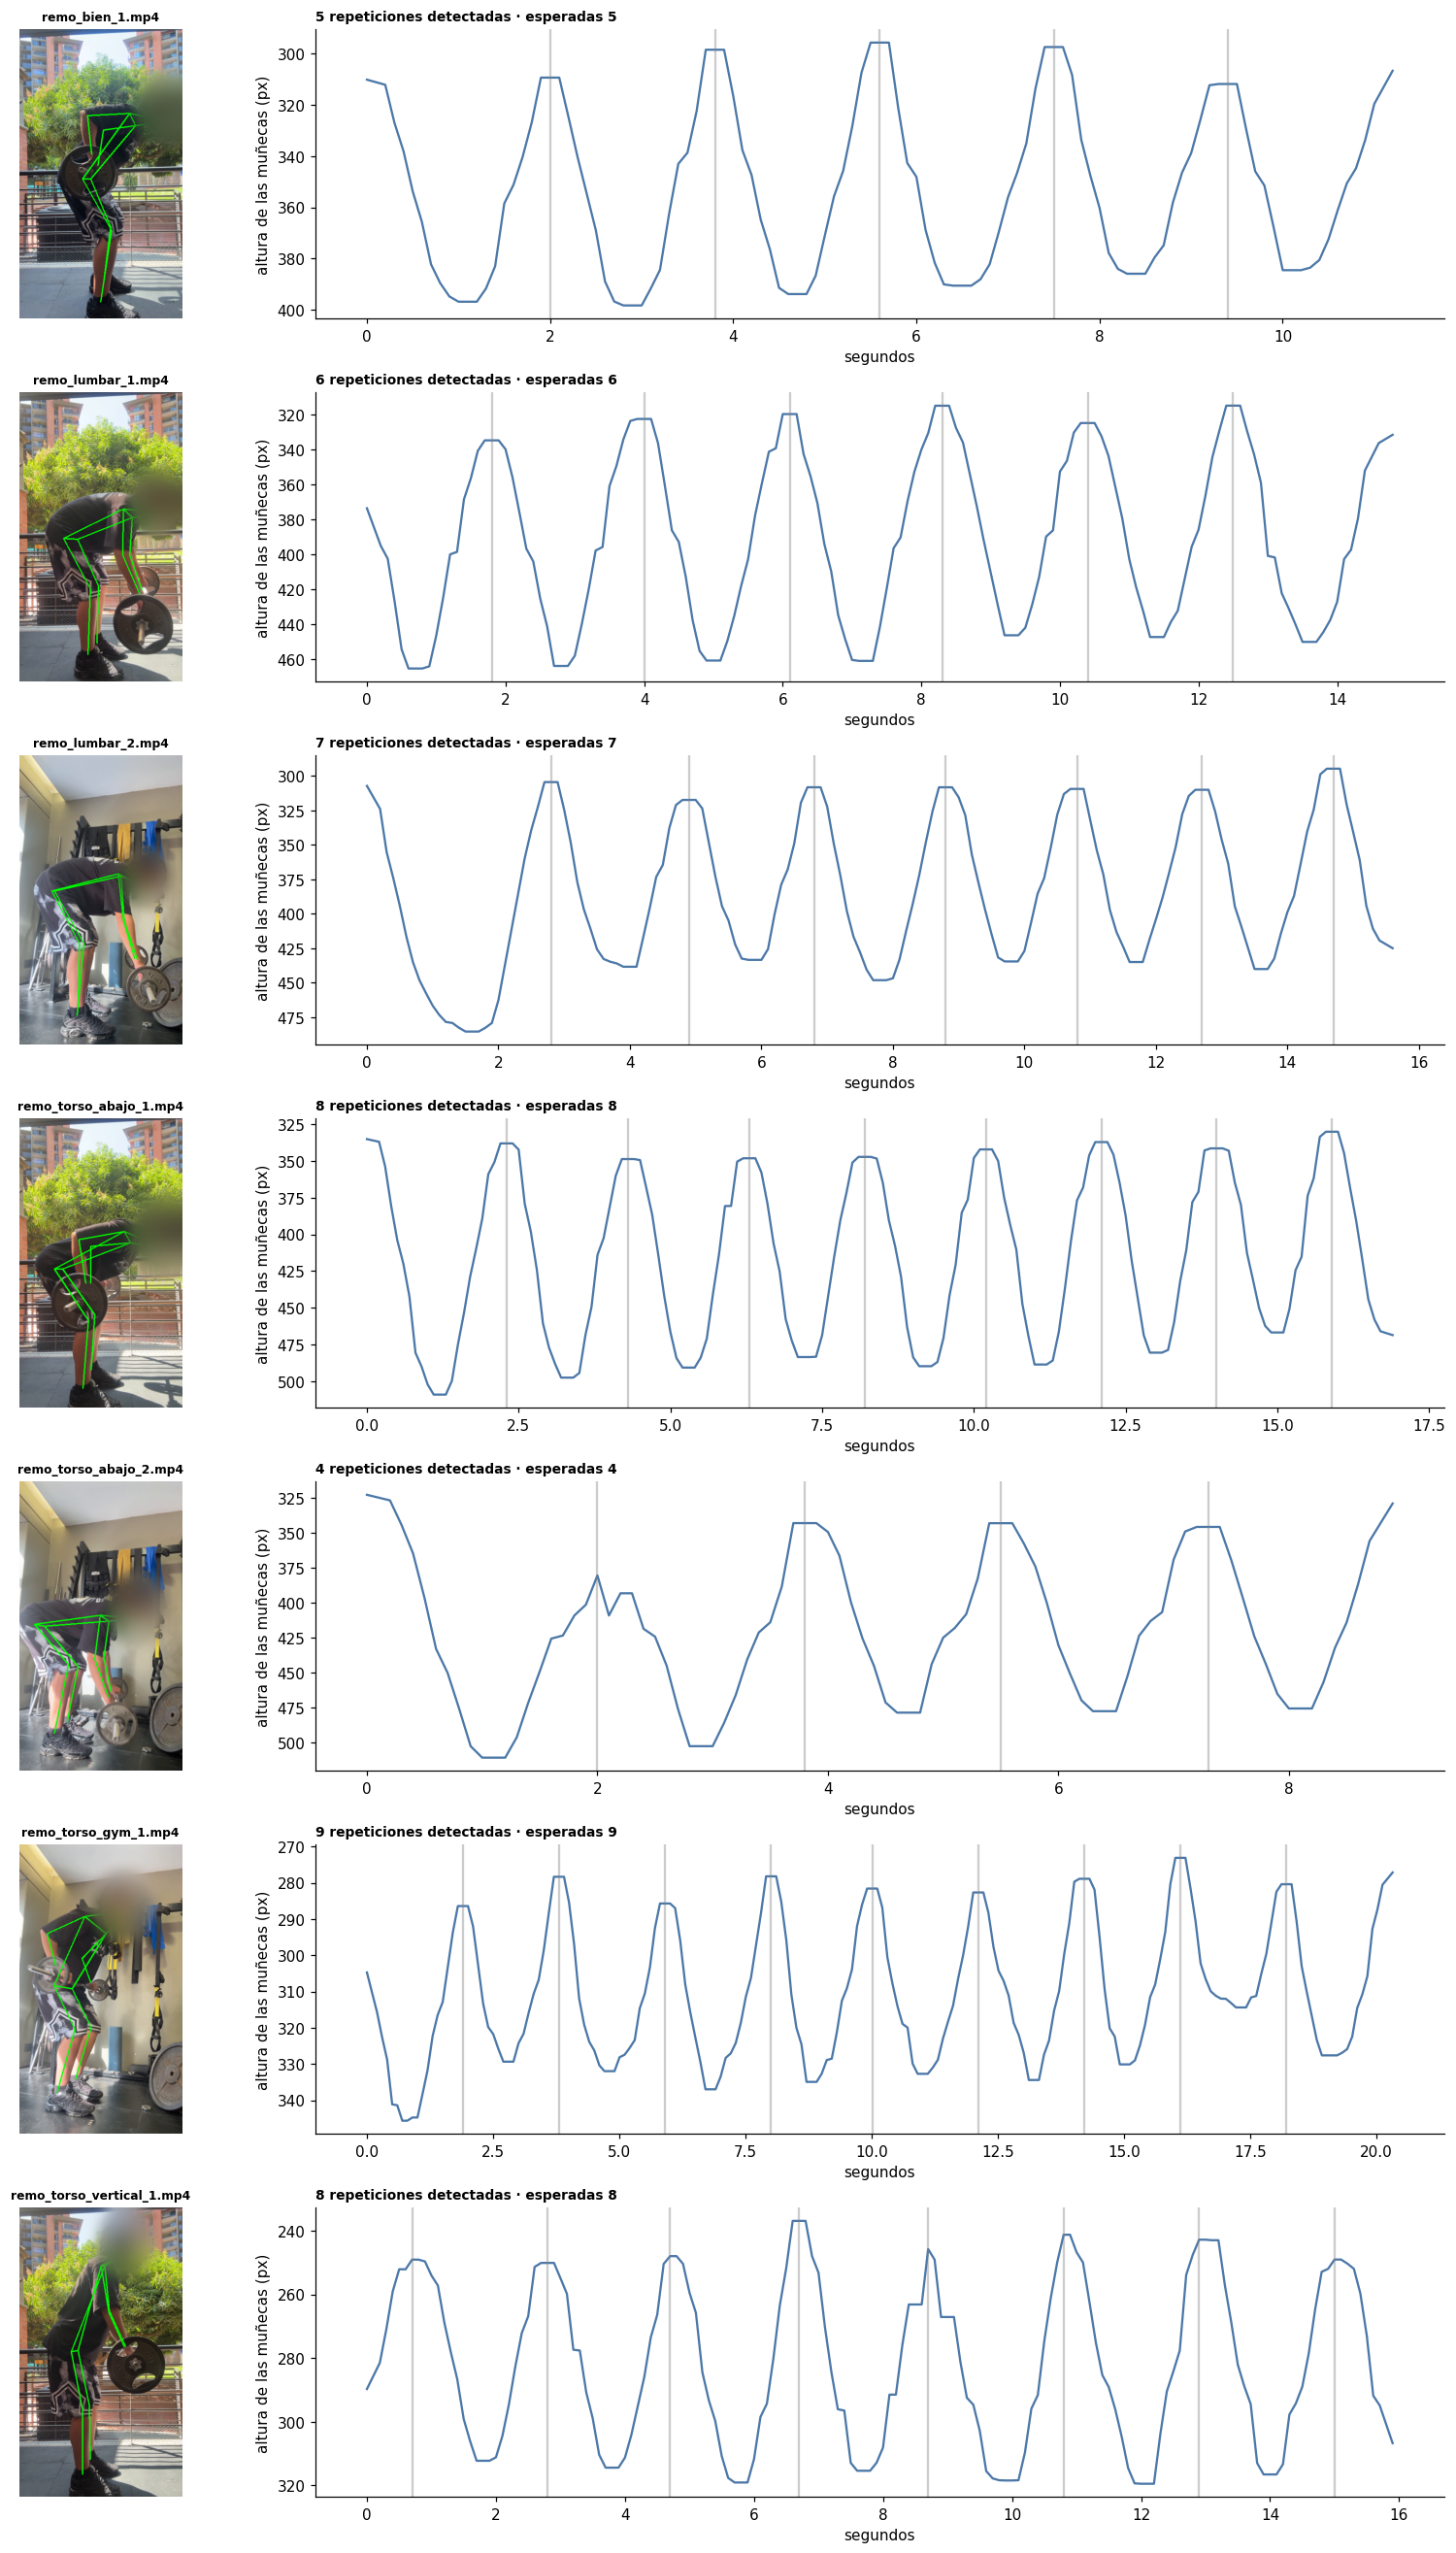

In [10]:
def leer_video(ruta):
    """Fotogramas a 10 por segundo, con el lado mayor a 640 px. Los iPhone guardan el giro aparte: si OpenCV no lo aplicó, se aplica aquí."""
    cap = cv2.VideoCapture(str(ruta)); assert cap.isOpened(), f'No pude abrir {ruta.name}'
    cap.set(cv2.CAP_PROP_ORIENTATION_AUTO, 1)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30; giro = int(cap.get(cv2.CAP_PROP_ORIENTATION_META) or 0)
    paso = max(1, round(fps / 10)); fr, t, n = [], [], 0
    while True:
        ok, f = cap.read()
        if not ok:
            break
        if n % paso == 0:
            if giro in (90, 270) and f.shape[0] < f.shape[1]:
                f = cv2.rotate(f, cv2.ROTATE_90_CLOCKWISE if giro == 90 else cv2.ROTATE_90_COUNTERCLOCKWISE)
            fr.append(reducir(f)); t.append(n / fps)
        n += 1
    cap.release()
    return fr, np.array(t), fps


def senal_munecas(kps):
    """Altura de las muñecas en cada fotograma, con las que se vean: de perfil, la de atrás suele quedar tapada."""
    y = []
    for k in kps:
        v = [k[i, 1] for i in (9, 10) if k[i, 2] > UMB_KP]
        y.append(np.mean(v) if v else np.nan)
    y = pd.Series(y, dtype=float).interpolate(limit_direction='both').fillna(0)
    return y.rolling(5, center=True, min_periods=1).median().values


def separar_reps(mun, t=None, tramos=None):
    """Cada jalón es un pico: la muñeca en su punto más alto (en la imagen, la «y» más pequeña). La ventana se limita para no incluir pausas.
    Con `tramos` (segundos), cada tramo usa su propio recorrido, porque dos posturas pueden mover la muñeca distinto, y lo de afuera se ignora."""
    bordes = [(int(np.searchsorted(t, a)), int(np.searchsorted(t, b))) for a, b in tramos] if tramos else [(0, len(mun))]
    todos, lim = [], []
    for a0, b0 in bordes:
        s_ = mun[a0:b0]
        if not len(s_):
            continue
        rango = np.percentile(s_, 95) - np.percentile(s_, 5)
        pic = find_peaks(-s_, distance=PICOS['distancia'], prominence=max(PICOS['minimo_px'], PICOS['prominencia_relativa'] * rango))[0] + a0
        mitad = int(np.median(np.diff(pic)) / 2) if len(pic) > 1 else 20
        for k, p_ in enumerate(pic):
            a = max((pic[k - 1] + p_) // 2, p_ - mitad) if k else max(a0, p_ - mitad)
            b = min((p_ + pic[k + 1]) // 2, p_ + mitad) if k < len(pic) - 1 else min(b0, p_ + mitad)
            lim.append((int(a), int(b)))
        todos += pic.tolist()
    return np.array(todos, dtype=int), lim


def etiqueta_de(nombre):
    return next((t for t in ('bien', 'lumbar', 'torso') if t in nombre.lower()), None)


def procesar_video(ruta, est):
    """Pose, recortes y repeticiones de un video. Todavía no usa el modelo de errores."""
    fr, t, fps = leer_video(ruta); assert fr, f'{ruta.name} no tiene fotogramas'
    if PRUEBA:
        est.n = 0
    kps = np.stack([principal(est(f), *f.shape[:2]) for f in fr])
    crops = [recorte_jpg(f, caja(k, REC, *f.shape[:2])) for f, k in zip(fr, kps)]
    mun = senal_munecas(kps); pic, lim = separar_reps(mun, t, TRAMOS.get(ruta.name)); k_m = len(fr) // 2; muestra = fr[k_m].copy()
    for a, b in ESQUELETO:
        if kps[k_m, a, 2] > UMB_KP and kps[k_m, b, 2] > UMB_KP:
            cv2.line(muestra, tuple(int(v) for v in kps[k_m, a, :2]), tuple(int(v) for v in kps[k_m, b, :2]), (0, 255, 0), 2)
    return dict(nombre=ruta.name, etiqueta=etiqueta_de(ruta.stem), t=t, fps=fps, kps=kps, crops=crops, mun=mun, picos=pic, lim=lim, muestra=muestra, forma=fr[0].shape[:2])


def decidir_reps(info):
    """Misma regla que en la prueba: 8 fotos repartidas de la repetición, la más probable frente al umbral por repetición."""
    P = ensamble(fotos_de(info['crops'])); filas = []
    for r, (a, b) in enumerate(info['lim']):
        sel = np.unique(np.linspace(a, b - 1, min(8, b - a)).round().astype(int)); pm = P[sel].max(0)
        filas.append(dict(Video=info['nombre'], Etiqueta=info['etiqueta'], Repeticion=r + 1, Segundo=float(info['t'][info['picos'][r]]), Fotos=len(sel), P_lumbar=float(pm[0]), P_torso=float(pm[1]),
                          Dice_lumbar=bool(pm[0] >= UMB_REP['lumbar']), Dice_torso=bool(pm[1] >= UMB_REP['torso'])))
    return P, filas


VIDEOS = [p for p in recorrer(ENTRADA) if p.suffix.lower() in ('.mp4', '.mov', '.m4v', '.avi') and p.name.lower().startswith('remo_')] if CORRER_VIDEOS else []
INFO, LISTOS = {}, []
T_CONTEO = pd.DataFrame()
if not VIDEOS:
    print('No hay videos propios: esta parte se salta.' if CORRER_VIDEOS else 'Parte E desactivada.')
else:
    with Etapa('B · pose y conteo'):
        EST = Pose(DEVS[0]); print(f'Pose con {EST.tipo} · proveedor {EST.proveedor}')
        filas = []
        for v in VIDEOS:
            with Seguro(f'Pose de {v.name}'):
                i_ = procesar_video(v, EST); INFO[v.name] = i_
                n_ = len(i_['lim']); esp = REPETICIONES_ESPERADAS.get(v.stem, REPETICIONES_OTROS) if i_['etiqueta'] else None
                ok_ = n_ >= MINIMO_REPS and (esp is None or n_ == esp or ACEPTAR_CONTEO_DISTINTO)
                if ok_:
                    LISTOS.append(v.name)
                filas.append(dict(Video=v.name, Etiqueta=i_['etiqueta'] or 'sin etiqueta', Fotogramas=len(i_['t']), Segundos=round(float(i_['t'][-1]), 1), Alto=i_['forma'][0], Ancho=i_['forma'][1],
                                  Pct_con_persona=round(100 * float((i_['kps'][..., 2].max(1) > 0).mean()), 1), Repeticiones=n_, Esperadas=esp, Se_analiza=ok_))
        T_CONTEO = pd.DataFrame(filas); guardar_tabla(T_CONTEO, 'videos_conteo')
    for r in T_CONTEO.itertuples():
        if r.Alto < r.Ancho:
            print(f'⚠ {r.Video} quedó horizontal: revisa la imagen de abajo. Hay que grabar en vertical.')
        if not r.Se_analiza:
            print(f'⚠ {r.Video}: {r.Repeticiones} repeticiones, se esperaban {r.Esperadas}. No se usa. Revisa la curva, ajusta PICOS o repite el video.')
            NOTAS.append(f'{r.Video}: {r.Repeticiones} repeticiones detectadas de {r.Esperadas}; no se analizó.')
        elif r.Esperadas is not None and not pd.isna(r.Esperadas) and r.Repeticiones != r.Esperadas:
            NOTAS.append(f'{r.Video}: {r.Repeticiones} repeticiones de {r.Esperadas}; se aceptó el conteo distinto a mano.')
    with Seguro('Figura de pose y conteo'):
        fig, ax = plt.subplots(len(INFO), 2, figsize=(14, 3.4 * len(INFO)), squeeze=False, gridspec_kw=dict(width_ratios=[1, 4]), constrained_layout=True)
        for (a0, a1), i_ in zip(ax, INFO.values()):
            a0.imshow(i_['muestra'][:, :, ::-1]); a0.axis('off'); a0.set_title(i_['nombre'], fontsize=8)
            a1.plot(i_['t'], i_['mun'], color='#4C78A8')
            for p_ in i_['picos']:
                a1.axvline(i_['t'][p_], color='gray', alpha=.4)
            a1.invert_yaxis(); a1.set_ylabel('altura de las muñecas (px)'); a1.set_xlabel('segundos'); a1.set_title(f"{len(i_['picos'])} repeticiones detectadas" + (f" · esperadas {REPETICIONES_ESPERADAS.get(Path(i_['nombre']).stem, REPETICIONES_OTROS)}" if i_['etiqueta'] else ''), fontsize=9, loc='left')
        guardar_fig(fig, 'fig_videos_conteo')

### Pose y recorte del tronco en cada video

En cada fotograma, la pose da los puntos del cuerpo y de ahí sale la caja del recorte del tronco que entra al modelo. Sobre cada video se indica lo que el modelo marcó en sus repeticiones. La cara de los fotogramas está pixelada.

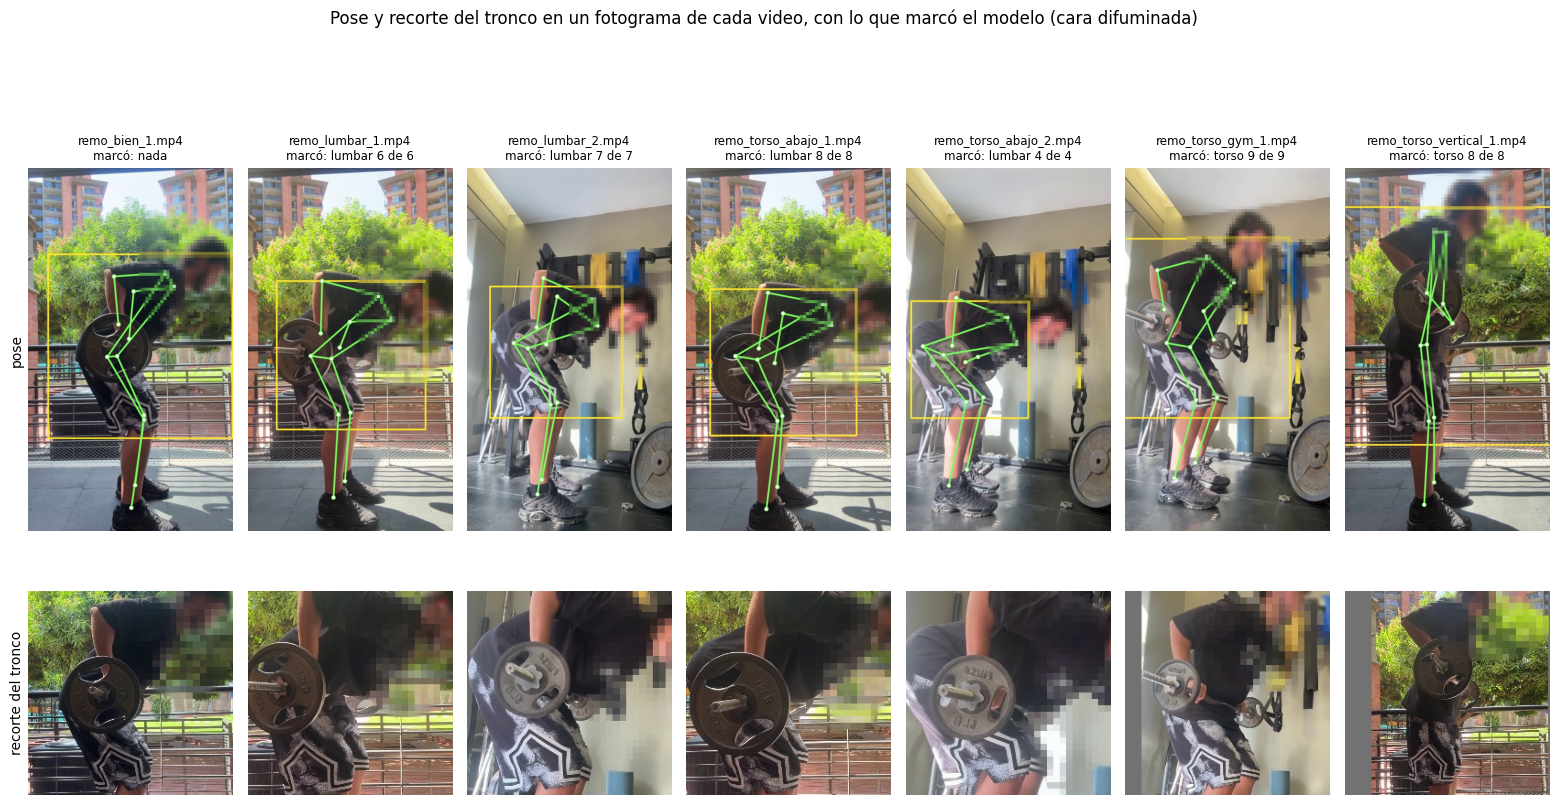

In [ ]:
# Figura armada aparte con un fotograma de cada video (la cara está pixelada).
# Lo que marcó el modelo sale de la tabla videos_repeticiones.csv de esta misma corrida.

## Paso 2. Lo que marca el modelo

Se usa el modelo final, sin reentrenar, con los umbrales por repetición del notebook 1. El recall es cuántas repeticiones con error marcó y la especificidad cuántas repeticiones correctas del video `bien` dejó sin marcar. Si el valor de la prueba queda por encima del IC exacto del 95 % del video, el desempeño bajó, y si queda por debajo, subió. Si queda dentro, no se puede afirmar nada. Con tan pocas repeticiones solo se notan cambios grandes, y al ser una sola persona el intervalo es optimista. La tabla cruzada muestra si el modelo confunde un error con otro.

── B · modelo en los videos · 0.21 h


,Video,Etiqueta,Repeticion,Segundo,Fotos,P_lumbar,P_torso,Dice_lumbar,Dice_torso
0,remo_bien_1.mp4,bien,1,2.000,8,0.038,0.000,False,False
1,remo_bien_1.mp4,bien,2,3.800,8,0.031,0.001,False,False
2,remo_bien_1.mp4,bien,3,5.600,8,0.121,0.002,False,False
3,remo_bien_1.mp4,bien,4,7.500,8,0.076,0.002,False,False
4,remo_bien_1.mp4,bien,5,9.400,8,0.032,0.002,False,False
5,remo_lumbar_1.mp4,lumbar,1,1.800,8,0.999,0.000,True,False
6,remo_lumbar_1.mp4,lumbar,2,4.000,8,0.999,0.000,True,False
7,remo_lumbar_1.mp4,lumbar,3,6.100,8,0.999,0.000,True,False
8,remo_lumbar_1.mp4,lumbar,4,8.300,8,0.999,0.000,True,False
9,remo_lumbar_1.mp4,lumbar,5,10.400,8,0.998,0.000,True,False


,Etiqueta,Repeticiones,Marca_lumbar,Marca_torso
0,bien,5,0,0
1,lumbar,13,13,0
2,torso,29,12,17


,Error,Metrica,Aciertos,De,Video,IC_exacto_video,Prueba,IC_prueba,Resultado
0,Lumbar,Recall,13,13,1.000,0.75–1.00,0.845,0.77–0.92,no se puede afirmar un cambio
1,Lumbar,Especificidad,5,5,1.000,0.48–1.00,0.943,0.91–0.97,no se puede afirmar un cambio
2,Torso,Recall,17,29,0.586,0.39–0.76,0.814,0.71–0.90,bajó
3,Torso,Especificidad,5,5,1.000,0.48–1.00,0.869,0.82–0.91,no se puede afirmar un cambio


Solo como referencia: dependen de la proporción de errores, que en los videos es muy distinta a la de la prueba.


,Error,Repeticiones,Proporcion_con_error,AP,AP_azar,Precision,F1
0,Lumbar,18,0.722,1.000,0.722,1.0,1.000
1,Torso,34,0.853,0.926,0.853,1.0,0.739


── B · modelo en los videos: 0.3 min


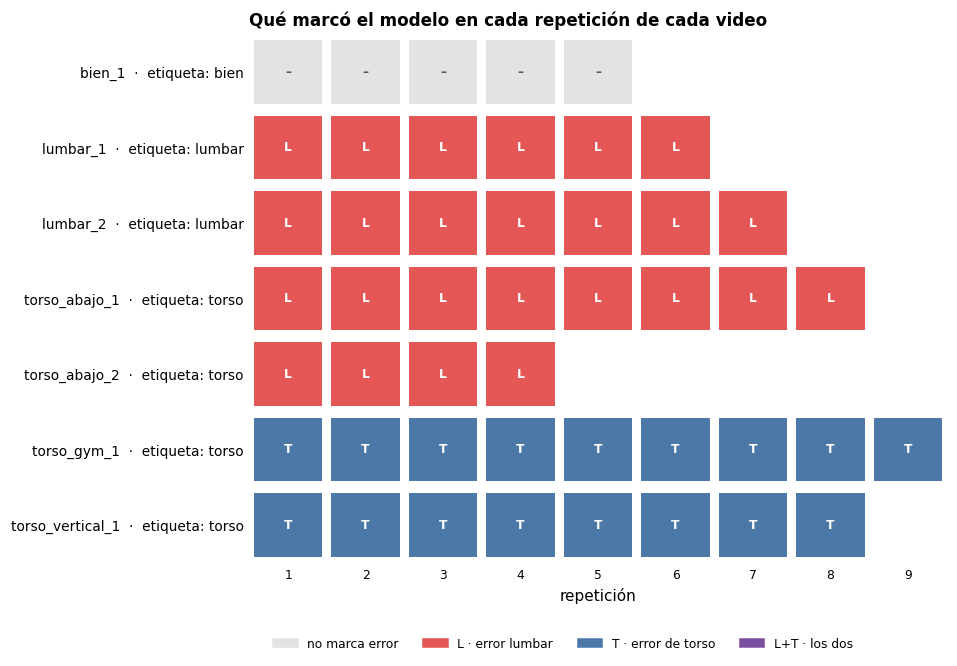

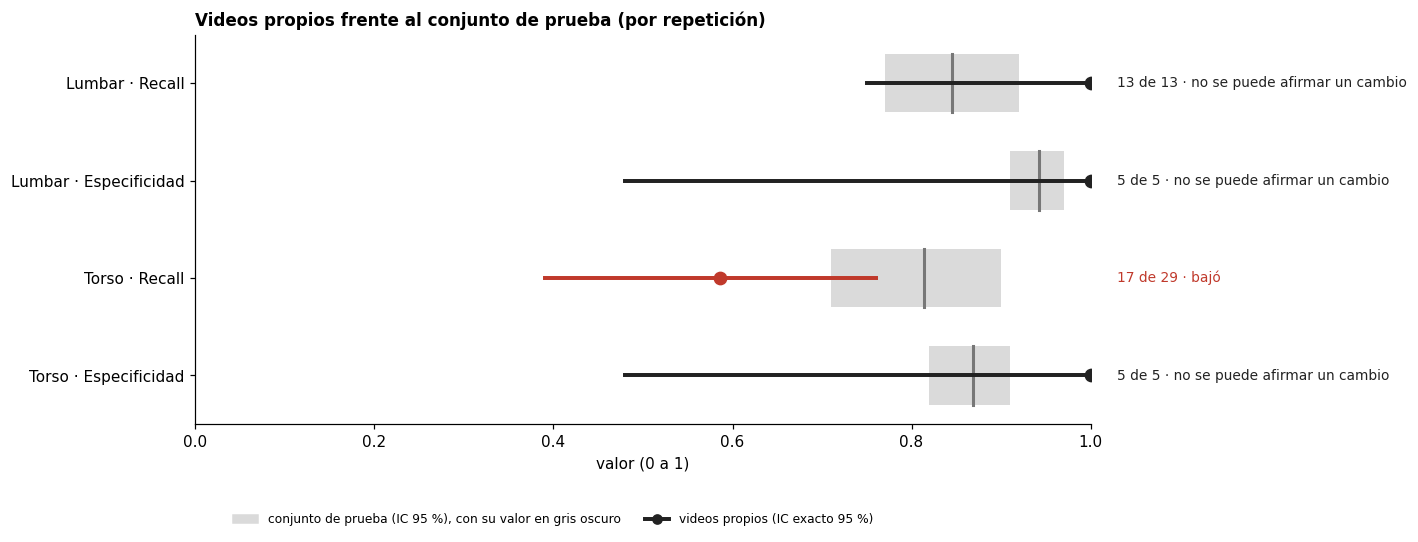

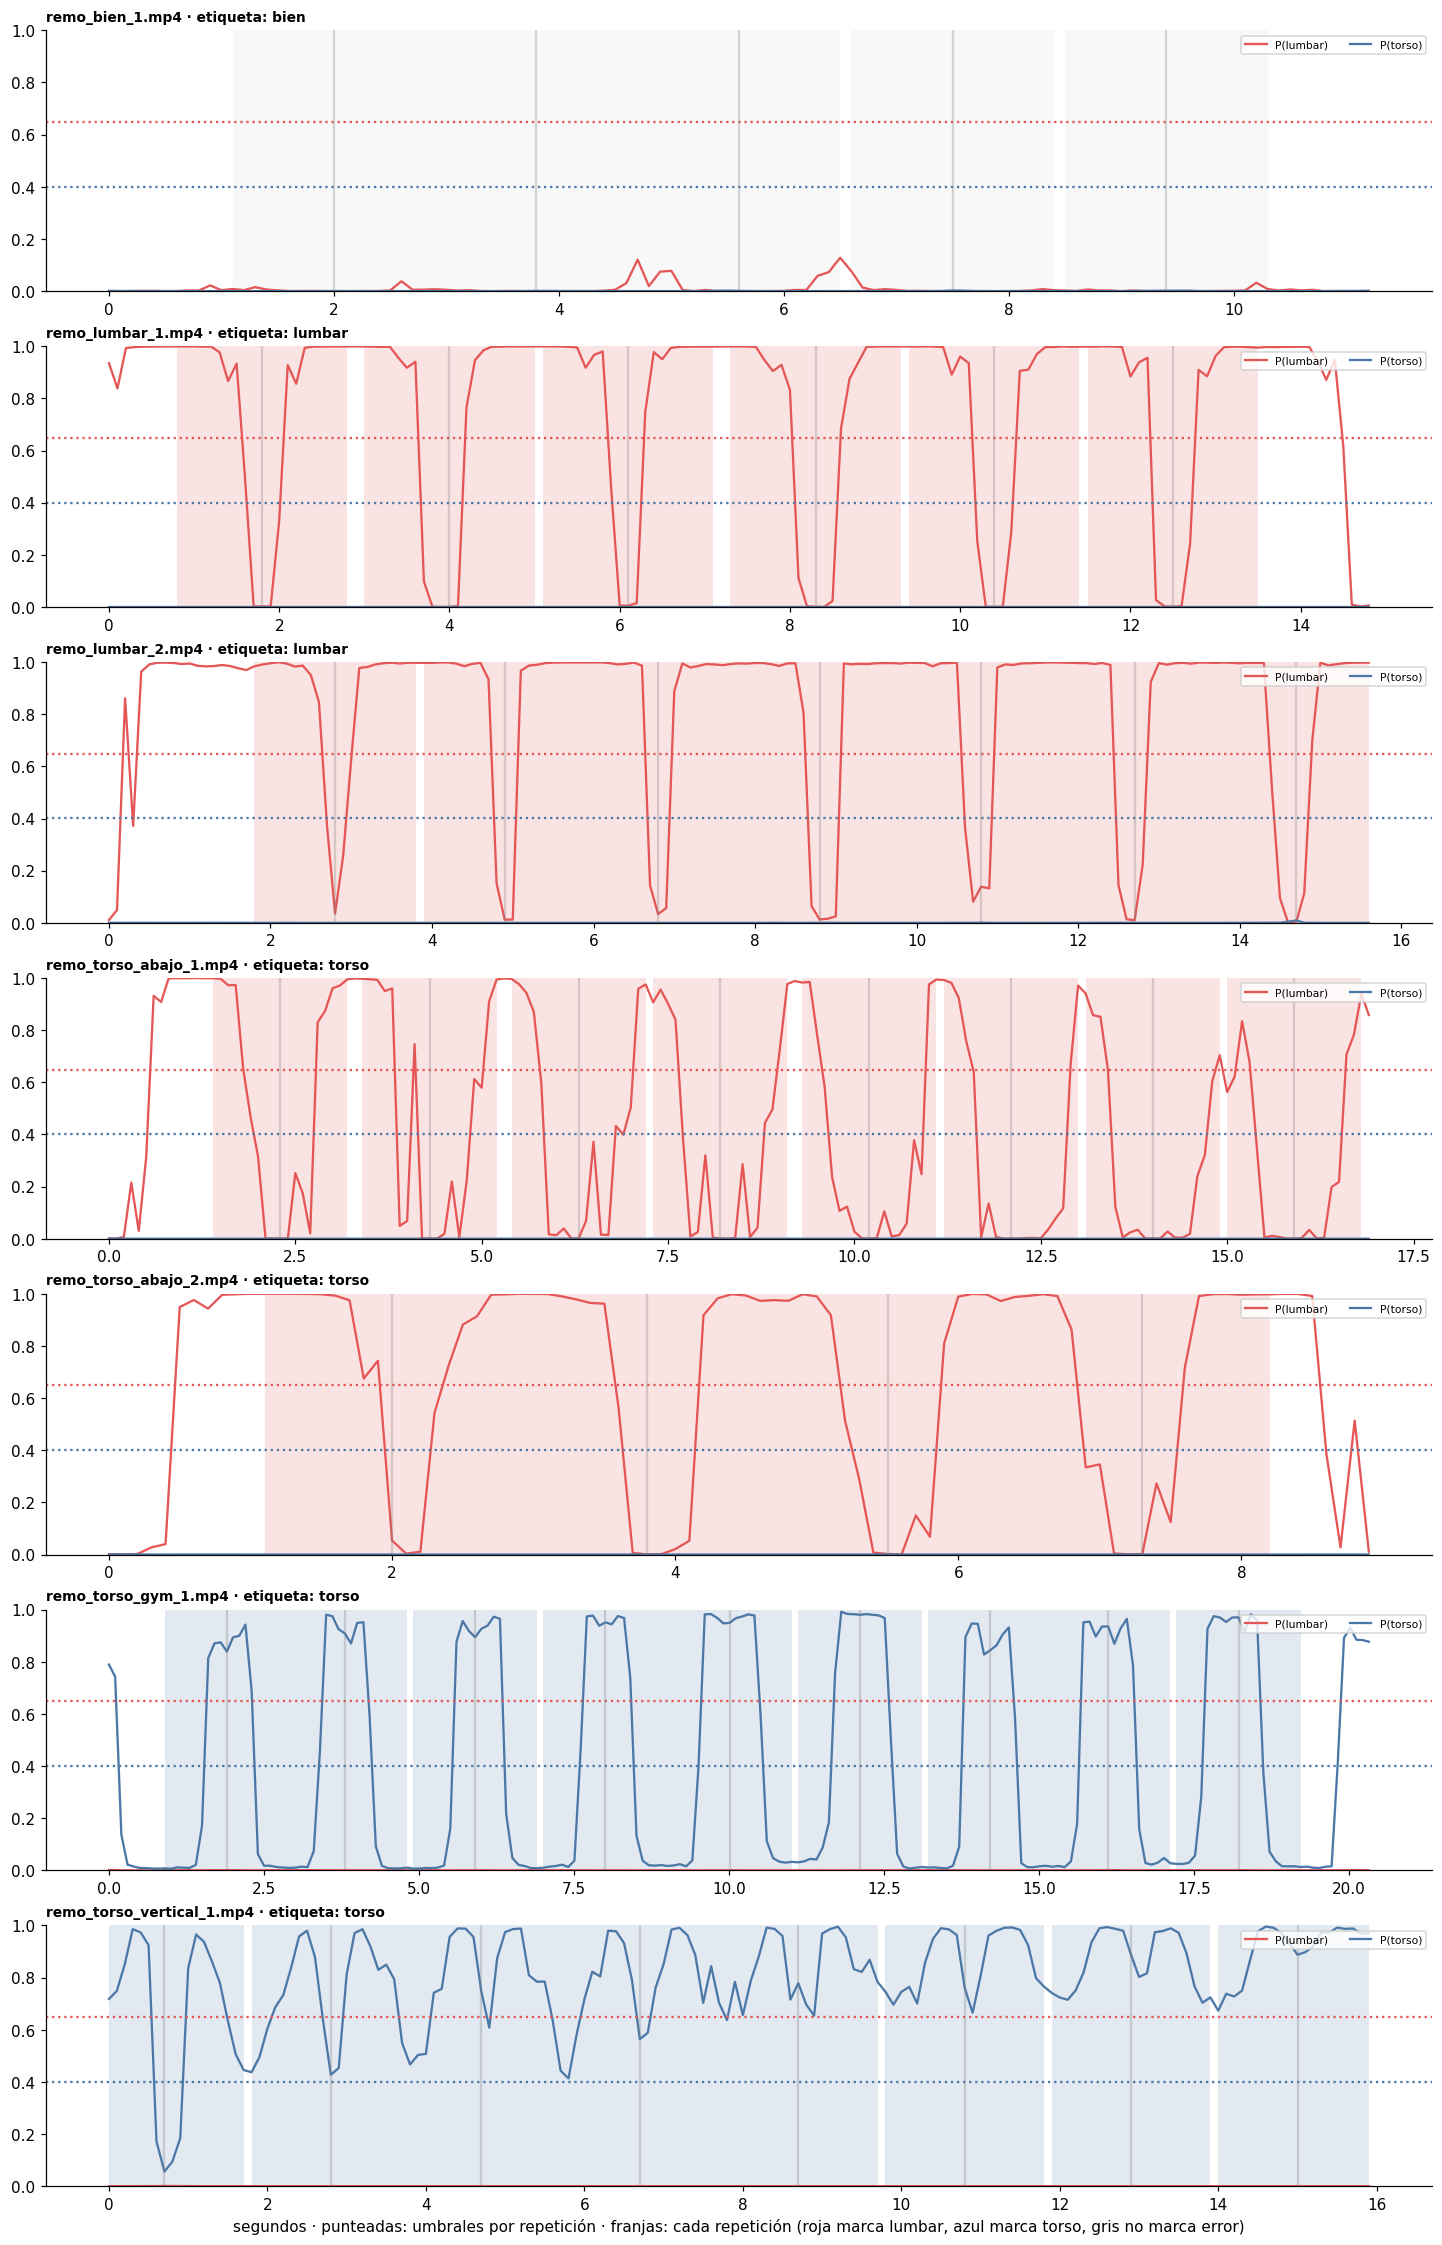

In [11]:
def ic_exacto(k, n):
    """Intervalo exacto del 95 % (Clopper-Pearson) para k aciertos de n."""
    if n == 0:
        return np.nan, np.nan
    return (0. if k == 0 else float(beta.ppf(.025, k, n - k + 1))), (1. if k == n else float(beta.ppf(.975, k + 1, n - k)))


def frente_a_prueba(valor, lo, hi):
    if not np.isfinite(lo):
        return 'sin datos'
    return 'bajó' if valor > hi else ('subió' if valor < lo else 'no se puede afirmar un cambio')


T_PROP, T_COMP, T_CRUCE, T_REFER, T_CAL = (pd.DataFrame() for _ in range(5))
if LISTOS:
    with Etapa('B · modelo en los videos'):
        filas, CURVAS = [], {}
        for n_ in LISTOS:
            P_, f_ = decidir_reps(INFO[n_]); filas += f_; CURVAS[n_] = P_
        T_PROP = pd.DataFrame(filas); guardar_tabla(T_PROP.round(3), 'videos_repeticiones')
        con_et = T_PROP[T_PROP.Etiqueta.notna()]

        def comparar(d_et):
            filas, filas_r = [], []
            for e in ERR:
                d_p, d_n = d_et[d_et.Etiqueta == e], d_et[d_et.Etiqueta == 'bien']
                if not len(d_p) and not len(d_n):
                    continue
                k_r, n_r = int(d_p[f'Dice_{e}'].sum()), len(d_p); k_e, n_e = int((~d_n[f'Dice_{e}']).sum()), len(d_n)
                fr_ = T_REP[T_REP.Error == NOMBRE_ERR[e]].iloc[0]
                for met_, k_, n2, val_, ic_p in (('Recall', k_r, n_r, fr_.Recall, fr_.Recall_IC), ('Especificidad', k_e, n_e, fr_.Especificidad, fr_.Especificidad_IC)):
                    lo, hi = ic_exacto(k_, n2)
                    filas.append(dict(Error=NOMBRE_ERR[e], Metrica=met_, Aciertos=k_, De=n2, Video=k_ / n2 if n2 else np.nan, IC_exacto_video=f'{lo:.2f}–{hi:.2f}' if n2 else '–',
                                      Prueba=val_, IC_prueba=ic_p, Resultado=frente_a_prueba(val_, lo, hi)))
                if len(d_p) and len(d_n):
                    d_ = pd.concat([d_p, d_n]); y_ = (d_.Etiqueta == e).values.astype(int); p_ = d_[f'P_{e}'].values
                    r_ = met(y_, p_, UMB_REP[e])
                    filas_r.append(dict(Error=NOMBRE_ERR[e], Repeticiones=len(d_), Proporcion_con_error=float(y_.mean()), AP=r_['AP'], AP_azar=float(y_.mean()), Precision=r_['Precision'], F1=r_['F1']))
            return pd.DataFrame(filas), pd.DataFrame(filas_r)

        if len(con_et):
            T_CRUCE = con_et.groupby('Etiqueta', as_index=False).agg(Repeticiones=('Repeticion', 'count'), Marca_lumbar=('Dice_lumbar', 'sum'), Marca_torso=('Dice_torso', 'sum'))
            guardar_tabla(T_CRUCE, 'videos_tabla_cruzada')
        T_COMP, T_REFER = comparar(con_et)
        if len(T_COMP):
            guardar_tabla(T_COMP.round(3), 'videos_frente_a_prueba')
        if len(T_REFER):
            print('Solo como referencia: dependen de la proporción de errores, que en los videos es muy distinta a la de la prueba.')
            guardar_tabla(T_REFER.round(3), 'videos_referencia')
    with Seguro('Figura: qué marcó el modelo en cada repetición'):
        from matplotlib.patches import Patch
        orden_ = {'bien': 0, 'lumbar': 1, 'torso': 2}
        vids_ = sorted(T_PROP.Video.unique(), key=lambda v: (orden_.get(etiqueta_de(Path(v).stem), 3), v)); nmax_ = int(T_PROP.groupby('Video').Repeticion.max().max())
        col_ = {(0, 0): '#E3E3E3', (1, 0): '#E45756', (0, 1): '#4C78A8', (1, 1): '#7B4FA0'}; txt_ = {(0, 0): '–', (1, 0): 'L', (0, 1): 'T', (1, 1): 'L+T'}
        fig, ax = plt.subplots(figsize=(2.6 + 0.62 * nmax_, 0.62 * len(vids_) + 1.9))
        for y_, v_ in enumerate(vids_):
            for r_ in T_PROP[T_PROP.Video == v_].itertuples():
                k_ = (int(r_.Dice_lumbar), int(r_.Dice_torso))
                ax.add_patch(plt.Rectangle((r_.Repeticion - 1 + .06, y_ + .08), .88, .84, color=col_[k_], lw=0))
                ax.text(r_.Repeticion - .5, y_ + .5, txt_[k_], ha='center', va='center', fontsize=8, color='#555' if k_ == (0, 0) else 'white', fontweight='bold')
        ax.set_xlim(0, nmax_); ax.set_ylim(len(vids_), 0)
        ax.set_yticks([y_ + .5 for y_ in range(len(vids_))]); ax.set_yticklabels([f"{Path(v_).stem.replace('remo_', '')}  ·  etiqueta: {etiqueta_de(Path(v_).stem) or 'ninguna'}" for v_ in vids_], fontsize=9)
        ax.set_xticks([i_ + .5 for i_ in range(nmax_)]); ax.set_xticklabels(range(1, nmax_ + 1), fontsize=8); ax.set_xlabel('repetición'); ax.tick_params(length=0)
        for sp_ in ax.spines.values():
            sp_.set_visible(False)
        ax.set_title('Qué marcó el modelo en cada repetición de cada video', fontweight='bold', fontsize=11, loc='left')
        ax.legend(handles=[Patch(color=col_[(0, 0)], label='no marca error'), Patch(color=col_[(1, 0)], label='L · error lumbar'), Patch(color=col_[(0, 1)], label='T · error de torso'), Patch(color=col_[(1, 1)], label='L+T · los dos')],
                  loc='upper center', bbox_to_anchor=(0.45, -0.12), ncol=4, fontsize=8, frameon=False)
        guardar_fig(fig, 'fig_videos_mapa')
    with Seguro('Figura: videos frente a la prueba'):
        if len(T_COMP):
            import re as re_
            from matplotlib.patches import Patch

            def rango_(t):
                x_ = re_.findall(r'\d+\.\d+|\d+', str(t)); return float(x_[0]), float(x_[1])
            fl_ = list(T_COMP.itertuples()); fig, ax = plt.subplots(figsize=(10.5, 0.75 * len(fl_) + 1.6))
            for y_, r_ in enumerate(fl_):
                tl_, th_ = rango_(r_.IC_prueba); ax.add_patch(plt.Rectangle((tl_, y_ - .3), th_ - tl_, .6, color='#DADADA', lw=0, zorder=1)); ax.plot([r_.Prueba] * 2, [y_ - .3, y_ + .3], color='#777', lw=2, zorder=2)
                if r_.De:
                    vl_, vh_ = rango_(r_.IC_exacto_video); c_ = {'bajó': '#C0392B', 'subió': '#2E86C1'}.get(r_.Resultado, '#222')
                    ax.plot([vl_, vh_], [y_, y_], color=c_, lw=2.6, zorder=3); ax.plot(r_.Video, y_, 'o', color=c_, ms=8, zorder=4)
                    ax.text(1.03, y_, f'{r_.Aciertos} de {r_.De} · {r_.Resultado}', va='center', fontsize=9, color=c_)
                else:
                    ax.text(1.03, y_, 'sin datos', va='center', fontsize=9, color='#777')
            ax.set_xlim(0, 1); ax.set_ylim(len(fl_) - .5, -.5); ax.set_yticks(range(len(fl_))); ax.set_yticklabels([f'{r_.Error} · {r_.Metrica}' for r_ in fl_]); ax.set_xlabel('valor (0 a 1)')
            ax.legend(handles=[Patch(color='#DADADA', label='conjunto de prueba (IC 95 %), con su valor en gris oscuro'), plt.Line2D([], [], color='#222', marker='o', lw=2.6, label='videos propios (IC exacto 95 %)')],
                      loc='upper center', bbox_to_anchor=(0.4, -0.2), ncol=2, fontsize=8, frameon=False)
            for sp_ in ('top', 'right'):
                ax.spines[sp_].set_visible(False)
            ax.set_title('Videos propios frente al conjunto de prueba (por repetición)', fontweight='bold', fontsize=11, loc='left')
            guardar_fig(fig, 'fig_videos_frente_a_prueba')
    with Seguro('Figura de los videos'):
        fig, ax = plt.subplots(len(LISTOS), 1, figsize=(13, 2.9 * len(LISTOS)), squeeze=False, constrained_layout=True)
        for a, n_ in zip(ax[:, 0], LISTOS):
            i_ = INFO[n_]; a.plot(i_['t'], CURVAS[n_][:, 0], color='#E45756', label='P(lumbar)'); a.plot(i_['t'], CURVAS[n_][:, 1], color='#4C78A8', label='P(torso)')
            a.axhline(UMB_REP['lumbar'], color='#E45756', ls=':'); a.axhline(UMB_REP['torso'], color='#4C78A8', ls=':')
            for r_, (a_, b_) in enumerate(i_['lim']):
                f_ = T_PROP[(T_PROP.Video == n_) & (T_PROP.Repeticion == r_ + 1)].iloc[0]
                c_ = '#7B4FA0' if (f_.Dice_lumbar and f_.Dice_torso) else ('#E45756' if f_.Dice_lumbar else ('#4C78A8' if f_.Dice_torso else '#BBBBBB'))
                a.axvspan(i_['t'][a_], i_['t'][min(b_, len(i_['t']) - 1)], color=c_, alpha=.16 if c_ != '#BBBBBB' else .10, lw=0)
            for p_ in i_['picos']:
                a.axvline(i_['t'][p_], color='gray', alpha=.3)
            a.set_ylim(0, 1); a.set_title(f"{n_} · etiqueta: {i_['etiqueta'] or 'ninguna'}", fontsize=9, loc='left'); a.legend(fontsize=7, loc='upper right', ncol=2)
        ax[-1, 0].set_xlabel('segundos · punteadas: umbrales por repetición · franjas: cada repetición (roja marca lumbar, azul marca torso, gris no marca error)'); guardar_fig(fig, 'fig_videos_probabilidades')

# Conclusiones

Los cambios de iluminación y el desenfoque leve casi no afectaron los resultados. La mayor variación fue de 0,02 en el error lumbar al aumentar el brillo de la imagen. Con el desenfoque fuerte sí hubo una caída de aproximadamente 0,05. En cambio, los giros afectaron bastante más la detección del torso: la AP pasó de 0,82 a 0,73 y 0,76 con ±5°, a 0,53 y 0,59 con ±10°, y finalmente a 0,28 y 0,32 con ±20°. Para el error lumbar la caída fue menor, llegando a 0,85 con un giro de -20°. Esto puede deberse a que al girar la imagen también cambia el ángulo en el que se observa el torso, aunque la etiqueta del error sigue siendo la misma.

En los videos propios, el modelo detectó las 13 repeticiones con error lumbar y no marcó ninguna de las cinco repeticiones correctas. Para el torso, identificó 17 de las 29 repeticiones con error (recall de 0,59), un resultado inferior al 0,81 obtenido en la prueba. De las 12 que no identificó como error de torso, el modelo marcó todas como error lumbar.

Hay que tener en cuenta que esta evaluación se hizo con una sola persona, en dos lugares y con etiquetas basadas en la técnica que se quería realizar al grabar. Además, la cantidad de repeticiones fue pequeña, por lo que estos resultados no son suficientes para asegurar que el rendimiento se mantenga fuera del conjunto de datos.

In [15]:
# ============================================================
# Guardar resultados
# ============================================================
json.dump(limpio(dict(horas=horas(), notas=NOTAS, tiempos=TIEMPOS, modelo=CFG['nombre_final'], videos=list(INFO), analizados=LISTOS)),
          open(OUT / 'results_validaciones.json', 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
zr = OUT.parent / 'resultados_validaciones.zip'
with zipfile.ZipFile(zr, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file():
            z.write(p, p.relative_to(OUT.parent))
print(f'Listo en {horas():.2f} h · {zr} ({zr.stat().st_size / 1e6:.1f} MB)')

Listo en 0.22 h · /kaggle/working/resultados_validaciones.zip (2.5 MB)
